# The integrity gate that vouches for the corpus, and the controls that make the engine refuse

**Question:** Does the load-time gate catch a transcription error, and which layer catches which?

**Level 4: Beyond the state of the art** · Needs: 01-the-data/01-the-corpus-and-the-cases, 01-the-data/02-geometry-reconstruction · Reading time: about 30 minutes

## Objectives

A table copied from a paper is only as good as the copy, and a wrong cell does not announce itself: the predictors fit it and return numbers. Fragmenta puts two safeguards around its data: a gate that runs on every load of the corpus (claim BS-3) and a refusal rule for blasts that no predictor should price (claim BS-2). This notebook tests both the way a sceptic would, by planting errors and watching what answers.

By the end you will have:

- recomputed the 28 statistics the paper prints from the shipped rows and seen how much margin the gate gives each one;
- planted six realistic defects in copies of the corpus, one per cell, and probed each layer of the gate on its own for each of them;
- read which layer catches which defect and how far each defect moves a printed statistic, and seen what the defects do downstream when nobody checks;
- asked twelve predictors about a site that has no scale and about six designs that are not blasts, and seen who answers.

## Setup

Install the packages with the exact pins of `notebooks/requirements.txt`. The engine is `blastfrag`, published on PyPI; the other packages are its numerical base and the plotting library.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

The single setup cell below imports the packages, prints their installed versions so the output records which engine produced every number, adds the product's `data-pipeline/` folder to the import path (the design guard of Step 7 lives there), sets the plotting style and defines `show_table`, a four-line helper that renders rows as a Markdown table because the notebook environment has no `pandas`.

In [1]:
# Imports, versions, the pipeline path, the plotting style and a table helper
import dataclasses
import sys
from decimal import Decimal
from importlib.metadata import version
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from matplotlib.colors import ListedColormap

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")

sys.path.insert(0, str(Path("../../../data-pipeline")))
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})


def show_table(header, rows, left=1):
    # Render the rows as a Markdown table, the first `left` columns left-aligned and the others right-aligned
    lines = ["| " + " | ".join(header) + " |", "|" + ":---|" * left + "---:|" * (len(header) - left)]
    lines += ["| " + " | ".join(str(cell) for cell in row) + " |" for row in rows]
    text = "\n".join(lines)
    display({"text/markdown": text, "text/plain": text}, raw=True)

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Data

Two sources, and no file under `data/` is read: the controls run live.

| Source | Owner and URL | Licence class | File the notebook reads |
|---|---|---|---|
| The 97 rows, the 28 printed descriptive statistics and the pinned digest | Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 | numeric facts reused with citation; the article never ships | the table, `PUBLISHED_DESCRIPTIVE_STATS` and `DATASET_DIGEST` inside the `blastfrag` wheel |
| The registry of cases and the design guard | this repository (MIT) | the product's own licence | `data-pipeline/pipeline/registry.py` and `data-pipeline/pipeline/model/blasts.py`, imported by path |

## Method

The gate that runs inside `load_training_corpus()` has two independent layers, and they answer different questions.

1. **The printed statistics.** The paper prints a minimum, a maximum, a mean and a standard deviation for each of the seven inputs. The gate recomputes all 28 from the shipped rows and compares each one at the precision it was printed to. A mismatch means the file is no longer the published table.
2. **The content digest.** A statistic is a weak witness to a single changed cell: correcting one powder factor moves a mean over 97 rows by less than a rounding step. A SHA-256 digest of the whole table, pinned in the engine, catches any change at all.

Both layers are called by `check_source_integrity` (Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 prints the statistics). The two steps below open one layer each.

### Step 1: the statistics layer

The paper prints 28 numbers: four statistics for each of seven inputs. The gate recomputes them from the shipped rows and compares each at the precision it was printed to: half a unit of the last printed digit for a minimum or a maximum, one unit for a mean or a standard deviation (the tolerances the engine applies, restated here as `ALLOWANCE`). The cell loads the corpus, calls the gate, recomputes the 28 statistics with a small function that later cells reuse, and lays them beside the printed values with the relative difference and the relative allowance of each.

In [2]:
# Recompute the statistics of every input and set them beside the printed ones
train = bf.load_training_corpus()
# Units of the last printed digit the gate allows
ALLOWANCE = {"minimum": 0.5, "maximum": 0.5, "mean": 1.0, "sd": 1.0}


def recomputed_statistics(rows):
    # (input, statistic, printed, recomputed, allowance) for the 28 printed statistics
    result = []
    for name, printed in bf.PUBLISHED_DESCRIPTIVE_STATS.items():
        values = np.array([getattr(b, name) for b in rows])
        found = {"minimum": values.min(), "maximum": values.max(), "mean": values.mean(), "sd": values.std(ddof=1)}
        for statistic, value in found.items():
            shown = getattr(printed, statistic)
            places = -Decimal(str(shown)).as_tuple().exponent
            result.append((name, statistic, shown, value, ALLOWANCE[statistic] * 10.0**-places))
    return result


bf.check_source_integrity(train)
print("gate on the shipped corpus: passed")
statistics = recomputed_statistics(train)
rows = []
for name, statistic, shown, value, allow in statistics:
    rows.append((name, statistic, shown, f"{value:.4f}", f"{abs(value - shown) / shown:.2%}", f"{allow / shown:.2%}"))
header = ["input", "statistic", "paper prints", "recomputed",
          "relative difference", "allowance"]
show_table(header, rows, left=2)

gate on the shipped corpus: passed


| input | statistic | paper prints | recomputed | relative difference | allowance |
|:---|:---|---:|---:|---:|---:|
| S_over_B | minimum | 1.0 | 1.0000 | 0.00% | 5.00% |
| S_over_B | maximum | 1.75 | 1.7500 | 0.00% | 0.29% |
| S_over_B | mean | 1.19 | 1.1890 | 0.09% | 0.84% |
| S_over_B | sd | 0.117 | 0.1168 | 0.20% | 0.85% |
| H_over_B | minimum | 1.33 | 1.3300 | 0.00% | 0.38% |
| H_over_B | maximum | 6.82 | 6.8200 | 0.00% | 0.07% |
| H_over_B | mean | 3.34 | 3.3452 | 0.15% | 0.30% |
| H_over_B | sd | 1.634 | 1.6337 | 0.02% | 0.06% |
| B_over_D | minimum | 17.98 | 17.9800 | 0.00% | 0.03% |
| B_over_D | maximum | 39.47 | 39.4700 | 0.00% | 0.01% |
| B_over_D | mean | 27.35 | 27.3549 | 0.02% | 0.04% |
| B_over_D | sd | 4.838 | 4.8386 | 0.01% | 0.02% |
| T_over_B | minimum | 0.5 | 0.5000 | 0.00% | 10.00% |
| T_over_B | maximum | 4.67 | 4.6700 | 0.00% | 0.11% |
| T_over_B | mean | 1.26 | 1.2628 | 0.22% | 0.79% |
| T_over_B | sd | 0.674 | 0.6739 | 0.02% | 0.15% |
| Pf_kg_m3 | minimum | 0.22 | 0.2200 | 0.00% | 2.27% |
| Pf_kg_m3 | maximum | 1.26 | 1.2600 | 0.00% | 0.40% |
| Pf_kg_m3 | mean | 0.53 | 0.5292 | 0.16% | 1.89% |
| Pf_kg_m3 | sd | 0.236 | 0.2355 | 0.23% | 0.42% |
| XB_m | minimum | 0.02 | 0.0200 | 0.00% | 25.00% |
| XB_m | maximum | 2.35 | 2.3500 | 0.00% | 0.21% |
| XB_m | mean | 1.1 | 1.1067 | 0.61% | 9.09% |
| XB_m | sd | 0.533 | 0.5323 | 0.14% | 0.19% |
| E_GPa | minimum | 9.57 | 9.5700 | 0.00% | 0.05% |
| E_GPa | maximum | 60.0 | 60.0000 | 0.00% | 0.08% |
| E_GPa | mean | 29.46 | 29.4606 | 0.00% | 0.03% |
| E_GPa | sd | 17.879 | 17.8788 | 0.00% | 0.01% |

The gate passes, and the table shows how. Minimums and maximums reproduce exactly. The means and standard deviations differ from the printed values by up to 0.61 percent (the mean of the in situ block size, which the paper prints as 1.1 and the rows give as 1.1067), always inside the allowance that the last printed digit gives. The allowances differ enormously, because they are set by how many digits the paper printed: a minimum printed as 0.02 may differ by 25 percent, while the mean of the modulus, printed with four significant digits, may differ by 0.03 percent. So the table's lesson is not the pass but the margin: a defect can hide only inside the allowance of the statistic it touches.

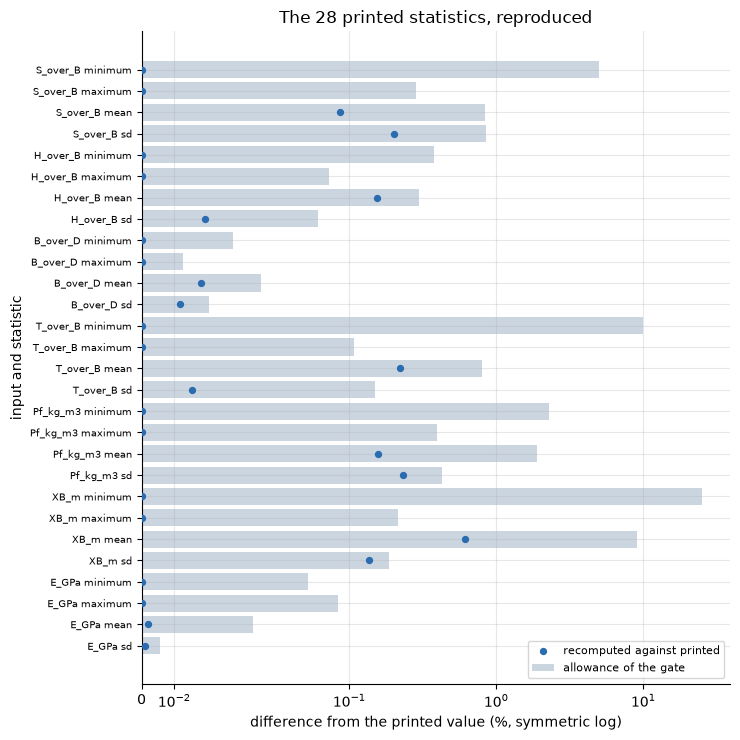

largest difference as a share of its allowance: 73%


In [3]:
# Difference of each recomputed statistic (dot) against the gate's allowance (bar)
labels = [f"{name} {statistic}" for name, statistic, *_ in statistics]
difference = [abs(value - shown) / shown * 100 for _, _, shown, value, _ in statistics]
allowed = [allow / shown * 100 for _, _, shown, _, allow in statistics]
positions = np.arange(len(statistics))
fig, ax = plt.subplots(figsize=(7.5, 7.5))
ax.barh(positions, allowed, color="#cbd5e0", label="allowance of the gate")
ax.scatter(difference, positions, s=18, color="#2b6cb0", zorder=3, label="recomputed against printed")
ax.set_xscale("symlog", linthresh=0.05)
ax.set_yticks(positions, labels, fontsize=7)
ax.invert_yaxis()
ax.set_ylabel("input and statistic")
ax.set_xlabel("difference from the printed value (%, symmetric log)")
ax.set_title("The 28 printed statistics, reproduced")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()
worst = max(abs(value - shown) / allow for _, _, shown, value, allow in statistics)
print("largest difference as a share of its allowance:", f"{worst:.0%}")

Each bar is the allowance of one statistic and each dot is the recomputed difference, on a symmetric logarithmic axis so that exact matches (the dots at zero) and differences of a few hundredths of a percent share one scale. Every dot lies inside its bar, and the largest sits at 73 percent of its allowance. Some bars are very short: the modulus statistics and the extremes of the burden-over-diameter ratio have allowances of hundredths of a percent, so a change there shows at once, while the stemming minimum and the block-size minimum, with allowances of 10 and 25 percent, are nearly blind. The figure shows how much room each statistic leaves a defect to hide; it does not say which defects exist.

### Step 2: the digest layer

A statistic is a weak witness: one changed cell among 97 rows usually moves a mean by less than its allowance. The second layer is a SHA-256 digest of the whole table, pinned in the engine as `DATASET_DIGEST` and recomputed from the rows by `compute_dataset_digest`. The cell shows the pinned digest, the digest of the shipped rows, and the digest of a copy in which a single measured size was mistyped, and counts how many of the 64 hexadecimal digits changed.

In [4]:
# The second layer: the pinned digest, the digest of the rows, and the digest after one edited cell
pinned = bf.datasets.DATASET_DIGEST
shipped = bf.datasets.compute_dataset_digest(train)
edited = [dataclasses.replace(b, x50_m=0.73) if b is train[0] else b for b in train]
changed = bf.datasets.compute_dataset_digest(edited)
rows = [("pinned in the engine", pinned[:20]), ("shipped rows", shipped[:20]),
        ("one cell edited: x50 of En1 0.37 typed 0.73", changed[:20])]
show_table(["digest", "SHA-256 (first 20 hex digits)"], rows)
print("shipped equals pinned:", shipped == pinned)
differ = sum(a != b for a, b in zip(shipped, changed))
print("hex digits that differ after the edit:", differ, "of", len(shipped))

| digest | SHA-256 (first 20 hex digits) |
|:---|---:|
| pinned in the engine | 9a72094d641a2557be4f |
| shipped rows | 9a72094d641a2557be4f |
| one cell edited: x50 of En1 0.37 typed 0.73 | b266b5621d79f4335ddb |

shipped equals pinned: True
hex digits that differ after the edit: 60 of 64


The shipped rows reproduce the pinned digest, and one mistyped cell changes 60 of the 64 hexadecimal digits: the digest is not a measure of similarity but a seal that says identical or different, never how different. That is its strength, since it catches any change at all, and its limit: it cannot tell a harmless change from a harmful one, and it can be pinned only after someone has compared the table with the paper, which is what the statistics layer does. The layers answer two questions. The statistics say the file still is the published table; the digest says it has not moved since.

## State of the art

Three facts from the product's research basis (the SDD) frame what is already known.

- The corpus is a published table. Hudaverdi, Kulatilake and Kuzu 2010 (https://doi.org/10.1002/nag.957) print it together with its own summary statistics, which is what makes an independent check possible at all.
- The SDD research basis records that a copy of the table held in the lab's vault carried five transcription defects, two of them on the regression target, found only by comparing every cell with the paper's tables. A study that reuses a copied table without that comparison inherits such defects silently.
- The studies that fit learned predictors to these rows (Amoako, Jha and Zhong 2022, https://doi.org/10.3390/mining2020013; Sui et al. 2025, https://doi.org/10.3390/app15031254) report predictors of the seven inputs. A trained regressor returns a number for any input vector and has no declared domain in which it declines to answer, so whether a rock volume and a charge can be known for a blast is outside what such a predictor can express.

The usual practice is therefore to take a copied table on trust and to let every predictor answer everything. The next section measures what each habit costs.

## Beyond the state of the art

Two claims are tested here, by planting errors and watching what answers.

**Claim BS-3, the load-time integrity gate.** Every load of the corpus reproduces the paper's printed statistics and a pinned digest. The test plants six realistic defects, one per cell, in copies of the corpus and probes each layer on its own, then measures what the defects that get through would do downstream.

**Claim BS-2, abstention as a first-class result.** A predictor that cannot know a rock volume must say so instead of answering. The test asks twelve predictors about the one site with no scale and about six designs that are not blasts.

### Step 3: probe each layer on its own

`check_source_integrity` raises one `ContractViolation` that lists every problem it found. To say which layer fired, the cell defines `statistics_complaint`, which calls the gate with `check_digest=False` and returns its first complaint (or `None`), and checks the digest layer by comparing the digest of the rows with the pinned one. The first probe runs on the clean corpus, where both must report nothing.

In [5]:
# A probe for the statistics layer, run on its own, and the digest check on the clean corpus
def statistics_complaint(rows):
    # The first complaint of the statistics layer, or None when it passes
    try:
        bf.check_source_integrity(rows, check_digest=False)
    except bf.ContractViolation as violation:
        lines = str(violation).splitlines()
        return lines[1].strip() if len(lines) > 1 else lines[0]
    return None


planted = {}
print("statistics layer on the clean corpus:", statistics_complaint(train))
print("digest differs on the clean corpus:", bf.datasets.compute_dataset_digest(train) != pinned)

statistics layer on the clean corpus: None
digest differs on the clean corpus: False


On the clean corpus the statistics layer has no complaint and the digest matches the pinned one, so any complaint that follows comes from a planted defect and not from the instrument.

### Defect 1: the historical error

The gate was written after a copy of the table was found with a powder-factor maximum of 1.47 where the paper prints 1.26. The cell plants exactly that error in the row with the largest powder factor and probes both layers.

In [6]:
# Defect 1: powder-factor maximum typed 1.47, paper prints 1.26
label = "powder-factor maximum 1.26 typed as 1.47"
peak = max(train, key=lambda b: b.Pf_kg_m3)
planted[label] = [dataclasses.replace(b, Pf_kg_m3=1.47) if b is peak else b for b in train]
complaint = statistics_complaint(planted[label])
print("statistics layer:", complaint or "passes")
digest = bf.datasets.compute_dataset_digest(planted[label])
print("digest of the copy:", digest[:12], "| pinned:", pinned[:12], "| differs:", digest != pinned)

statistics layer: Pf_kg_m3.max: computed 1.470000, the source paper prints 1.26
digest of the copy: 6e46ed378d83 | pinned: 9a72094d641a | differs: True


The statistics layer names the statistic (`Pf_kg_m3.max`) and both numbers, the computed 1.47 against the printed 1.26, which is the most useful message the gate can give because it says where to look. The digest also differs, and says only that something changed.

### Defect 2: a lost decimal point

The first blast, En1 of Enusa, has a rock modulus of 60.0 GPa, and a slip writes 6.0. The modulus is the one input that identifies a campaign, so a wrong value here would quietly create a rock that does not exist.

In [7]:
# Defect 2: rock modulus 60.0 typed as 6.0
label = "modulus 60.0 typed as 6.0"
planted[label] = [dataclasses.replace(b, E_GPa=6.0) if b is train[0] else b for b in train]
complaint = statistics_complaint(planted[label])
print("statistics layer:", complaint or "passes")
digest = bf.datasets.compute_dataset_digest(planted[label])
print("digest of the copy:", digest[:12], "| pinned:", pinned[:12], "| differs:", digest != pinned)

statistics layer: E_GPa.min: computed 6.000000, the source paper prints 9.57
digest of the copy: 00710021b249 | pinned: 9a72094d641a | differs: True


The statistics layer catches it on the minimum: the computed minimum is now 6.0 while the paper prints 9.57. A change of a decade in the extreme of an input cannot hide, and the digest differs as well.

### Defect 3: a slip in the second decimal

The stemming ratio of the first blast, 0.78, is typed as 0.79. This is the typo that every reader makes and no reader sees: a change of 0.01 in one cell out of 97 rows.

In [8]:
# Defect 3: stemming ratio 0.78 typed as 0.79
label = "stemming ratio 0.78 typed as 0.79"
planted[label] = [dataclasses.replace(b, T_over_B=0.79) if b is train[0] else b for b in train]
complaint = statistics_complaint(planted[label])
print("statistics layer:", complaint or "passes")
digest = bf.datasets.compute_dataset_digest(planted[label])
print("digest of the copy:", digest[:12], "| pinned:", pinned[:12], "| differs:", digest != pinned)

statistics layer: passes
digest of the copy: 91171a7ad249 | pinned: 9a72094d641a | differs: True


The statistics layer passes: no printed statistic moves enough to leave its allowance. Only the digest catches it. Here the statistics layer misses a defect that is really there, and the matrix below measures the size of the gap.

### Defect 4: a transposed measurement

The measured size of the first blast, 0.37 m, is typed as 0.73 m. This is the regression target, the value every predictor is scored against, so it is the defect that matters most downstream; but the paper prints no summary statistic of the measured size, so nothing in the statistics layer can see it.

In [9]:
# Defect 4: measured size 0.37 typed as 0.73
label = "measured size 0.37 typed as 0.73"
planted[label] = [dataclasses.replace(b, x50_m=0.73) if b is train[0] else b for b in train]
complaint = statistics_complaint(planted[label])
print("statistics layer:", complaint or "passes")
digest = bf.datasets.compute_dataset_digest(planted[label])
print("digest of the copy:", digest[:12], "| pinned:", pinned[:12], "| differs:", digest != pinned)

statistics layer: passes
digest of the copy: b266b5621d79 | pinned: 9a72094d641a | differs: True


The statistics layer passes because the measured size is not among the 28 printed statistics, and only the digest catches the change. The most damaging defect of the six is invisible to the layer built from the paper's own summary.

### Defect 5: a blast under the wrong campaign

The first blast of Enusa is filed under Reocin. No number changes, but the campaign is the unit that every later protocol holds out, so a mislabelled row quietly moves a blast from one campaign into another.

In [10]:
# Defect 5: a blast filed under the wrong campaign
label = "blast filed under the wrong campaign"
planted[label] = [dataclasses.replace(b, site="Reocin") if b is train[0] else b for b in train]
complaint = statistics_complaint(planted[label])
print("statistics layer:", complaint or "passes")
digest = bf.datasets.compute_dataset_digest(planted[label])
print("digest of the copy:", digest[:12], "| pinned:", pinned[:12], "| differs:", digest != pinned)

statistics layer: passes
digest of the copy: 7510e9063b32 | pinned: 9a72094d641a | differs: True


The statistics layer passes, because a label is not a statistic, and the digest catches it. This is the defect that no summary of the numbers can ever see.

### Defect 6: a lost row

A copy that has lost its first row has 96 blasts instead of 97, as happens when a table is pasted from a spreadsheet and a line is cut.

In [11]:
# Defect 6: a row lost in a copy
label = "one row lost"
planted[label] = train[1:]
complaint = statistics_complaint(planted[label])
print("statistics layer:", complaint or "passes")
digest = bf.datasets.compute_dataset_digest(planted[label])
print("digest of the copy:", digest[:12], "| pinned:", pinned[:12], "| differs:", digest != pinned)

statistics layer: the training corpus is 97 blasts, got 96
digest of the copy: 1b4df22bcb89 | pinned: 9a72094d641a | differs: True


The statistics layer stops at once with `the training corpus is 97 blasts, got 96`, before computing any statistic, because the row count is the first thing the gate checks. The digest differs too.

### Step 4: the detection matrix

The cell probes the six copies again and collects the verdict of each layer and of the full gate. It also measures how far each defect moves the 28 printed statistics: for each statistic the change from its clean value divided by its allowance, and the largest of the 28. A defect that moves some statistic by more than one allowance cannot hide from the statistics layer; one that moves nothing that far can.

In [12]:
# Detection matrix: which layer fires, and how far each defect moves the printed statistics
clean = {(n, s): value for n, s, _, value, _ in recomputed_statistics(train)}
matrix, movement = [], []
for label, copy in planted.items():
    statistics_layer = statistics_complaint(copy) is not None
    digest_layer = bf.datasets.compute_dataset_digest(copy) != pinned
    moved = max(abs(v - clean[(n, s)]) / allow for n, s, _, v, allow in recomputed_statistics(copy))
    matrix.append((statistics_layer, digest_layer, statistics_layer or digest_layer))
    movement.append(moved)
verdict = {True: "caught", False: "missed"}
rows = []
for label, row, moved in zip(planted, matrix, movement):
    rows.append((label, *(verdict[v] for v in row), f"{moved:.2f}"))
header = ["planted defect", "statistics layer", "digest layer",
          "full gate", "largest move, in allowances"]
show_table(header, rows)

| planted defect | statistics layer | digest layer | full gate | largest move, in allowances |
|:---|---:|---:|---:|---:|
| powder-factor maximum 1.26 typed as 1.47 | caught | caught | caught | 42.00 |
| modulus 60.0 typed as 6.0 | caught | caught | caught | 714.00 |
| stemming ratio 0.78 typed as 0.79 | missed | caught | caught | 0.07 |
| measured size 0.37 typed as 0.73 | missed | caught | caught | 0.00 |
| blast filed under the wrong campaign | missed | caught | caught | 0.00 |
| one row lost | caught | caught | caught | 184.26 |

The statistics layer caught three of the six, for sound reasons: the powder-factor and modulus slips moved a printed statistic by 42 and 714 allowances, and the lost row, besides failing the count, moved statistics by 184. The three it missed moved nothing beyond 0.07 allowances (the stemming slip) or nothing at all (the measured size and the campaign label, which no printed statistic involves). The digest layer caught all six, and so did the full gate.

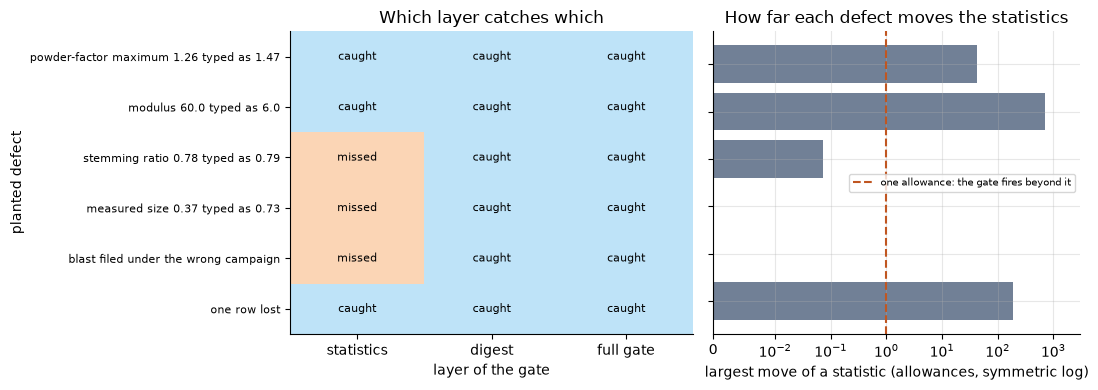

In [13]:
# Left: which layer fires for which defect. Right: how far it moves a statistic
names = list(planted)
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.1, 1]})
left.imshow(np.array(matrix, dtype=float), cmap=ListedColormap(["#fbd5b5", "#bee3f8"]), aspect="auto")
for i, row in enumerate(matrix):
    for j, caught in enumerate(row):
        left.text(j, i, "caught" if caught else "missed", ha="center", va="center", fontsize=8)
left.set_xticks(range(3), ["statistics", "digest", "full gate"])
left.set_yticks(range(len(names)), names, fontsize=8)
left.set_ylabel("planted defect")
left.set_xlabel("layer of the gate")
left.set_title("Which layer catches which")
left.grid(False)
right.barh(range(len(names)), movement, color="#718096")
right.axvline(1.0, color="#c05621", ls="--", label="one allowance: the gate fires beyond it")
right.set_xscale("symlog", linthresh=0.01)
right.set_xlim(0, 3000)
right.set_yticks(range(len(names)), [""] * len(names))
right.invert_yaxis()
right.set_xlabel("largest move of a statistic (allowances, symmetric log)")
right.set_title("How far each defect moves the statistics")
right.legend(fontsize=7, loc="center right")
fig.tight_layout()
plt.show()

The left panel is the matrix: the digest column is full while the statistics column has three gaps, so the layers are not redundant, and the full gate inherits the digest's reach. The right panel says why, on a symmetric logarithmic axis: each bar is the largest move of a printed statistic in allowances, and the dashed line at one allowance is where the statistics layer fires. The three caught defects sit far beyond it, the stemming slip sits at 0.07, and the measured-size and campaign-label defects have no bar because they move no printed statistic. The figure does not show how many other defects the layers might miss; it shows that these six separate them.

### Step 5: what the missed defects do downstream

If nobody ran the gate, would anyone notice? The cell fits the engine's refitted regression, a power law over the seven ratios, on each corrupted copy, predicts the clean 97 rows with it, and reports the shift in the corpus mean size and the largest change in any prediction against a fit on the clean rows.

In [14]:
# What a user of a copied table would see downstream of each defect
reference = np.array([p.x50_m for p in bf.RefittedRegression().fit(train).predict(train)])
rows = []
for label, copy in planted.items():
    predictions = np.array([p.x50_m for p in bf.RefittedRegression().fit(copy).predict(train)])
    shift = bf.training_mean(copy) - bf.training_mean(train)
    rows.append((label, f"{shift:+.4f}", f"{np.abs(predictions - reference).max():.4f}"))
header = ["planted defect", "shift of the mean x50 (m)",
          "largest prediction change of a refitted regression (m)"]
show_table(header, rows)

| planted defect | shift of the mean x50 (m) | largest prediction change of a refitted regression (m) |
|:---|---:|---:|
| powder-factor maximum 1.26 typed as 1.47 | +0.0000 | 0.0050 |
| modulus 60.0 typed as 6.0 | +0.0000 | 0.0102 |
| stemming ratio 0.78 typed as 0.79 | +0.0000 | 0.0009 |
| measured size 0.37 typed as 0.73 | +0.0037 | 0.0578 |
| blast filed under the wrong campaign | +0.0000 | 0.0000 |
| one row lost | -0.0007 | 0.0102 |

The defects that slip past the statistics are small where they slip. The stemming slip changes a refitted prediction by at most 0.0009 m, under a millimetre; the mislabelled campaign changes nothing at all in a regression on the ratios; and the mistyped measured size moves the corpus mean by 0.0037 m and one prediction by 0.0578 m. Nobody would see these differences in a fit, which is exactly why they travel. The relabelled row is worse than the table suggests, since it would change which campaign a held-out protocol removes, an effect no refit can show.

### Step 6: the site with no scale

A predictor that needs a rock volume must not answer where none exists. The geometry control is the six Miami blasts, which no source gives a scale (notebook 02). The cell fits each of the twelve predictors (the engine's ladder without its two controls, the null model and the oracle) on the other nine campaigns, asks it about the six Miami blasts, and counts for each how many it answered and how many it refused, with the first reason it gave.

In [15]:
# Fit every predictor on the other nine campaigns and ask it about the six Miami blasts
miami = [b for b in train if b.site == "Miami"]
others = [b for b in train if b.site != "Miami"]
rows, reasons = [], {}
for name, build in bf.default_arms().items():
    if name in ("null", "oracle"):
        continue  # the two controls are not predictors under test
    predictions = build().fit(others).predict(miami)
    refused = [p for p in predictions if p.x50_m is None]
    reasons[name] = refused[0].abstain_reason if refused else "-"
    rows.append((name, reasons[name][:58] + " ..." if refused else "-", len(predictions) - len(refused), len(refused)))
header = ["predictor", "first refusal reason", "answered", "refused"]
show_table(header, rows, left=2)
print("svr-poly, full reason:", reasons["svr-poly"])

| predictor | first refusal reason | answered | refused |
|:---|:---|---:|---:|
| kuznetsov | Miami publishes no hole diameter, so rock volume and charg ... | 0 | 6 |
| kuznetsov-transfer | Miami publishes no hole diameter, so rock volume and charg ... | 0 | 6 |
| kuznetsov-capped | Miami publishes no hole diameter, so rock volume and charg ... | 0 | 6 |
| group-discriminant | this arm assigns a rock-stiffness group rather than a frag ... | 0 | 6 |
| published-regression | - | 6 | 0 |
| refitted-regression | - | 6 | 0 |
| published-neural-net | - | 6 | 0 |
| svr-rbf | - | 6 | 0 |
| svr-poly | the model returned -0.1446 m, which is outside the plausib ... | 3 | 3 |
| random-forest | - | 6 | 0 |
| xgboost | - | 6 | 0 |
| stacking | - | 6 | 0 |

svr-poly, full reason: the model returned -0.1446 m, which is outside the plausible fragment range 0.001 to 3.0 m. This is the model leaving its domain, not a prediction.


Seven predictors answer all six Miami blasts, because they use only the ratios and never need a length. The three classical predictors refuse all six, with a reason that names the missing diameter. The group discriminant refuses all six for a different reason, since it returns a rock-stiffness group and not a size, a refusal by design. The polynomial support-vector regression answers three and refuses three, because it returned negative sizes outside the plausible range of 0.001 to 3 m. So one table holds four kinds of behaviour, and every refusal explains itself. The table does not say the seven answers are right: they cannot be checked against a length that nobody published.

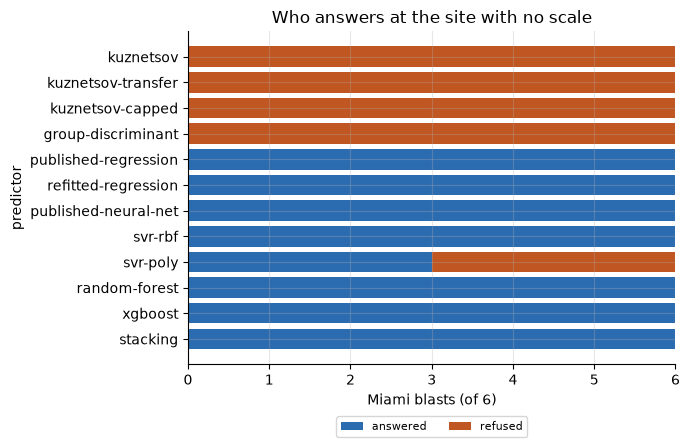

In [16]:
# Answered and refused Miami blasts of each predictor, from the table above
names = [row[0] for row in rows]
answered = np.array([row[2] for row in rows])
refused = np.array([row[3] for row in rows])
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.barh(names, answered, color="#2b6cb0", label="answered")
ax.barh(names, refused, left=answered, color="#c05621", label="refused")
ax.invert_yaxis()
ax.set_xlabel("Miami blasts (of 6)")
ax.set_ylabel("predictor")
ax.set_title("Who answers at the site with no scale")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=8)
fig.tight_layout()
plt.show()

Each bar is one predictor's six Miami blasts, blue where it answered and orange where it refused. The four fully orange bars are refusals, three because the scale is unknown and one by design; the single split bar, the polynomial support-vector regression, is a different mechanism, a guard on the plausibility of the output. The figure shows how selective refusal is: the engine does not refuse everywhere, only where an answer would be an invention. It does not show whether the blue answers deserve any trust on a site that no length can verify.

### Step 7: designs that are not blasts

The second control is six designs that are not blasts: a stemming of 4.60 burdens in a bench 1.40 burdens tall leaves no charge column. A model fitted on seven ratios knows nothing of this and will price them. The cell loads the six designs from the product's case registry, fits each of the twelve predictors on the full corpus and counts how many designs each prices when asked directly, then applies the pipeline's design guard `is_degenerate` and counts again.

In [17]:
# Price six designs whose stemming swallows the bench, then apply the pipeline's guard
from pipeline.model.blasts import blasts_for_case, is_degenerate
from pipeline.registry import get_case

designs = blasts_for_case(get_case("ctrl-degenerate"))
rows = []
for name, build in bf.default_arms().items():
    if name in ("null", "oracle"):
        continue
    predictions = build().fit(train).predict(designs)
    priced = sum(p.x50_m is not None for p in predictions)
    after = sum(p.x50_m is not None and is_degenerate(d) is None for p, d in zip(predictions, designs))
    rows.append((name, priced, after))
header = ["predictor", "designs priced directly (of 6)",
          "designs priced after the guard"]
show_table(header, rows)
print("designs refused by the guard:", sum(is_degenerate(d) is not None for d in designs), "of", len(designs))
for language in ("en", "es"):
    print(designs[0].blast_id, language, "-", is_degenerate(designs[0])[language])

| predictor | designs priced directly (of 6) | designs priced after the guard |
|:---|---:|---:|
| kuznetsov | 0 | 0 |
| kuznetsov-transfer | 6 | 0 |
| kuznetsov-capped | 0 | 0 |
| group-discriminant | 0 | 0 |
| published-regression | 6 | 0 |
| refitted-regression | 6 | 0 |
| published-neural-net | 6 | 0 |
| svr-rbf | 6 | 0 |
| svr-poly | 6 | 0 |
| random-forest | 6 | 0 |
| xgboost | 6 | 0 |
| stacking | 6 | 0 |

designs refused by the guard: 6 of 6
DG01 en - the stemming is 4.60 burdens in a bench 1.40 burdens tall, so there is no charge column. This is not a blast.
DG01 es - el taco mide 4,60 bordos en un banco de 1,40 bordos de alto, así que no hay columna de carga. Esto no es una voladura.


Nine of the twelve predictors price all six designs, among them the published regression, the neural network, the stacking ensemble and the transfer form of the classical equation, which predicts its own rock factor from the modulus. The three that do not answer do so by accident or by design: the two classical predictors with a site-constant factor have none for a synthetic site, and the group discriminant never returns a size. After the guard no predictor prices any design: the guard refuses all six, and its reason, printed above, is written in two languages in the product. It works on the design and not on the number, because there is no number that a ratio model would refuse.

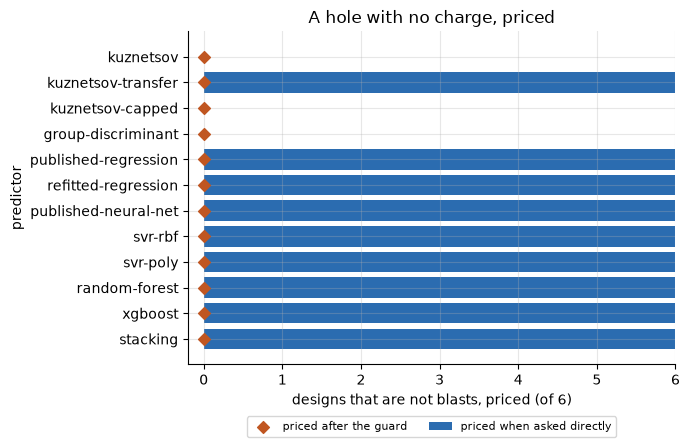

In [18]:
# Designs priced by each predictor directly (bars) and after the guard (marks)
names = [row[0] for row in rows]
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.barh(names, [row[1] for row in rows], color="#2b6cb0", label="priced when asked directly")
ax.scatter([row[2] for row in rows], names, color="#c05621", marker="D", zorder=3, label="priced after the guard")
ax.invert_yaxis()
ax.set_xlim(-0.2, len(designs))
ax.set_xlabel("designs that are not blasts, priced (of 6)")
ax.set_ylabel("predictor")
ax.set_title("A hole with no charge, priced")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=8)
fig.tight_layout()
plt.show()

The blue bars are the designs each predictor prices when asked directly, nine of the twelve at the full six; the orange diamonds are what remains after the guard, zero for every predictor. The figure shows that refusal is not something most predictors do on their own: it has to be added as a rule outside them. It does not show that the guard catches every design that is not a blast. It tests one rule, a stemming that swallows the bench, and a design that fails in another way would need another rule.

## Results

**Answer:** Yes, but only with both layers together. On the shipped rows the gate reproduces all 28 printed statistics inside their allowances, the largest at 73 percent of its allowance, and the pinned digest. Of six planted defects the statistics layer caught three (the powder-factor and modulus slips, which moved a printed statistic by 42 and 714 allowances, and a lost row) and missed three (a stemming slip, a mistyped measured size and a mislabelled campaign, which moved no statistic beyond 0.07 allowances); the digest layer caught all six. The refusal claim holds as well: four of twelve predictors refuse all six Miami blasts, and after the pipeline's guard none of them prices any of the six designs that are not blasts, although nine of the twelve price all six when asked directly.

**What follows.** Neither layer can be dropped. The statistics are what says the file still is the paper's table, and the digest is what keeps it from moving after that comparison; a copy checked by statistics alone passes with a mistyped target. The refusal of a design that is not a blast is a rule outside the predictors, and each new way a design can fail needs its own rule.

**What this notebook does not show.** Passing the gate shows the file is the published table, not that the published table is right about the blasts. The six defects are a sample, not a census of what can go wrong. And a refusal proves nothing about accuracy where a predictor does answer: the controls show that the engine declines where it must, not that it is correct where it does not. That question belongs to topics 04 and 05.

## Summary

- The gate has two layers: the paper's 28 printed statistics, compared at the precision they were printed to, and a pinned SHA-256 digest of the whole table (claim BS-3).
- Six planted defects separate them: the statistics caught three, the digest caught all six, and the three that only the digest sees include the mistyped measured size.
- Defects that slip past the statistics shift a refitted regression by 0.0009 m, by nothing or by 0.0578 m, differences nobody would notice in a fit without the digest.
- Of twelve predictors, four refuse the six Miami blasts and, after the design guard, none prices any of the six designs that are not blasts (claim BS-2).
- Next: topic 02 uses the reconstructed geometry to run the classical equation.

## References

- Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 (the table, its printed statistics, the defects found by comparison)
- Amoako, Jha and Zhong 2022, https://doi.org/10.3390/mining2020013 (learned predictors on the same rows)
- Sui, Zhou, Zhao, Yang and Zou 2025, https://doi.org/10.3390/app15031254 (the stacking ensemble and the field blasts)
- `blastfrag` 0.4.0, the engine, on PyPI: https://pypi.org/project/blastfrag/